In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import concurrent.futures

SEQ_LENGTH = 4
MAX_POSITION_SIZE = 1000  # Maximum number of shares to buy/sell at once
TRANSACTION_COST = 0.001  # 0.1% transaction cost
MARGIN_REQUIREMENT = 0.5  # 50% margin requirement for short selling
SLIPPAGE = 0.001  # 0.1% slippage

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='5m', start_date='2023-06-23', end_date='2023-06-30'):
    try:
        data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
        if data.empty:
            raise ValueError(f"No data found for {stock_code} with the given parameters.")
        data['RSI'] = compute_rsi(data['Close'])
        data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
        return data
    except Exception as e:
        print(f"Error fetching data for {stock_code}: {e}")
        return pd.DataFrame()

# Function to compute RSI
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if (col not in data.columns) or (data[col].isnull().any()):
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    short_shares = 0
    transactions = []
    portfolio_value = [initial_cash]

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            
            # Adjust for transaction costs and slippage
            buy_price = current_price * (1 + TRANSACTION_COST + SLIPPAGE)
            sell_price = current_price * (1 - TRANSACTION_COST - SLIPPAGE)
            
            # Trading logic
            if predicted_price > buy_price and cash > buy_price:
                shares_to_buy = min(cash // buy_price, MAX_POSITION_SIZE)
                if shares_to_buy > 0:
                    cash -= shares_to_buy * buy_price
                    shares += shares_to_buy
                    transactions.append(('buy', shares_to_buy, buy_price))
            
            elif predicted_price < sell_price and shares > 0:
                shares_to_sell = min(shares, MAX_POSITION_SIZE)
                if shares_to_sell > 0:
                    cash += shares_to_sell * sell_price
                    shares -= shares_to_sell
                    transactions.append(('sell', shares_to_sell, sell_price))
            
            # Short selling logic
            elif predicted_price < sell_price and cash > sell_price * MARGIN_REQUIREMENT:
                shares_to_short = min(cash // (sell_price * MARGIN_REQUIREMENT), MAX_POSITION_SIZE)
                if shares_to_short > 0:
                    cash += shares_to_short * sell_price
                    short_shares += shares_to_short
                    transactions.append(('short_sell', shares_to_short, sell_price))
            
            elif predicted_price > buy_price and short_shares > 0:
                shares_to_cover = min(short_shares, MAX_POSITION_SIZE)
                if shares_to_cover > 0:
                    cash -= shares_to_cover * buy_price
                    short_shares -= shares_to_cover
                    transactions.append(('cover_short', shares_to_cover, buy_price))
        
        # Calculate current portfolio value and append to the list
        current_portfolio_value = cash + shares * current_price - short_shares * current_price
        portfolio_value.append(current_portfolio_value)

    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1] - short_shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions, portfolio_value

# Function to backtest trading strategy
def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='30m', start_date=start_date, end_date=end_date)
    if historical_data.empty:
        print(f"Skipping backtesting for {stock_code} due to data fetching issues.")
        return None
    
    # Debug print to check the data range
    print(f"Historical data range for {stock_code}: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points for {stock_code}: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions, portfolio_value = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value for {stock_code}: {final_portfolio_value}")
    print(f"Returns for {stock_code}: {returns * 100:.2f}%")
    print(f"Transactions for {stock_code}: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
    
    # Plotting predicted vs actual prices
    plt.figure(figsize=(14, 7))
    plt.plot(timestamps, actual_prices, label='Actual Close Price', marker='o')
    plt.plot(timestamps, predicted_prices, label='Predicted Close Price', marker='x')
    plt.title(f'Actual vs Predicted Closing Prices for {stock_code}')
    plt.xlabel('Timestamp')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plotting portfolio value over time
    plt.figure(figsize=(14, 7))
    plt.plot(portfolio_value, label='Portfolio Value', marker='o')
    plt.title('Portfolio Value Over Time')
    plt.xlabel('Time Step')
    plt.ylabel('Portfolio Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return {
        'stock_code': stock_code,
        'initial_cash': initial_cash,
        'final_portfolio_value': final_portfolio_value,
        'returns': returns,
        'transactions': transactions,
        'portfolio_value': portfolio_value
    }

# List of top 5 DOW JONES stocks based on previous analysis
top_5_dow_jones_stocks = ['AAPL', 'MSFT', 'JNJ', 'V', 'WMT']

# Function to backtest a single stock
def backtest_single_stock(stock_code):
    model_path = f'model_{stock_code}.keras'
    scaler_path = f'scaler_{stock_code}.pkl'
    start_date = '2024-07-02'
    end_date = '2024-07-02'
    
    print(f"Backtesting for {stock_code}")
    result = backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date)
    if result:
        return result
    return None

# Backtest trading strategy for each of the top 5 stocks in parallel
results = []
with concurrent.futures.ThreadPoolExecutor() as executor:
    futures = [executor.submit(backtest_single_stock, stock) for stock in top_5_dow_jones_stocks]
    for future in concurrent.futures.as_completed(futures):
        result = future.result()
        if result:
            results.append(result)

# Sort results by returns and report the top 3
top_3_results = sorted(results, key=lambda x: x['returns'], reverse=True)[:3]

# Print overall results
for result in top_3_results:
    print(f"Stock: {result['stock_code']}")
    print(f"Initial Cash: {result['initial_cash']}")
    print(f"Final Portfolio Value: {result['final_portfolio_value']}")
    print(f"Returns: {result['returns'] * 100:.2f}%")
    print(f"Transactions: {result['transactions']}")
    print("\n")


Backtesting for AAPL
Backtesting for MSFT
Backtesting for JNJ
Backtesting for V
Backtesting for WMT


[*********************100%%**********************]  1 of 1 completed

2 Failed downloads:
['JNJ', 'V']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)')



[*********************100%%**********************]  1 of 1 completed

2 Failed downloads:
['JNJ', 'V', 'WMT']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)')

2 Failed downloads:

3 Failed downloads:

2 Failed downloads:
['JNJ', 'V', 'WMT']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)')
['JNJ', 'V', 'WMT']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)')
['JNJ', 'V', 'WMT']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)')


$JNJ: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)
$V: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)
$WMT: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)
Error fetching data for JNJ: No data found for JNJ with the given parameters.
Skipping backtesting for JNJ due to data fetching issues.
Error fetching data for AAPL: 'AAPL'
Skipping backtesting for AAPL due to data fetching issues.
Error fetching data for MSFT: 'MSFT'
Skipping backtesting for MSFT due to data fetching issues.
Error fetching data for V: No data found for V with the given parameters.
Skipping backtesting for V due to data fetching issues.
Error fetching data for WMT: No data found for WMT with the given parameters.
Skipping backtesting for WMT due to data fetching issues.
$MSFT: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)


$AAPL: possibly delisted; No price data found  (15m 2024-07-02 -> 2024-07-02)


Backtesting for AAPL
Backtesting for MSFT
Backtesting for JNJ
Backtesting for V
Backtesting for WMT


[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed



C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0


Error fetching data for JNJ: 'JNJ'
Skipping backtesting for JNJ due to data fetching issues.
Error fetching data for WMT: 'WMT'
Skipping backtesting for WMT due to data fetching issues.
Error fetching data for MSFT: 'MSFT'
Skipping backtesting for MSFT due to data fetching issues.
Error fetching data for AAPL: 'AAPL'
Skipping backtesting for AAPL due to data fetching issues.
Historical data range for V: 2024-07-01 09:30:00-04:00 to 2024-07-01 15:55:00-04:00
Number of data points for V: 78
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

... (7 outputs left out)

C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\1727540915.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━

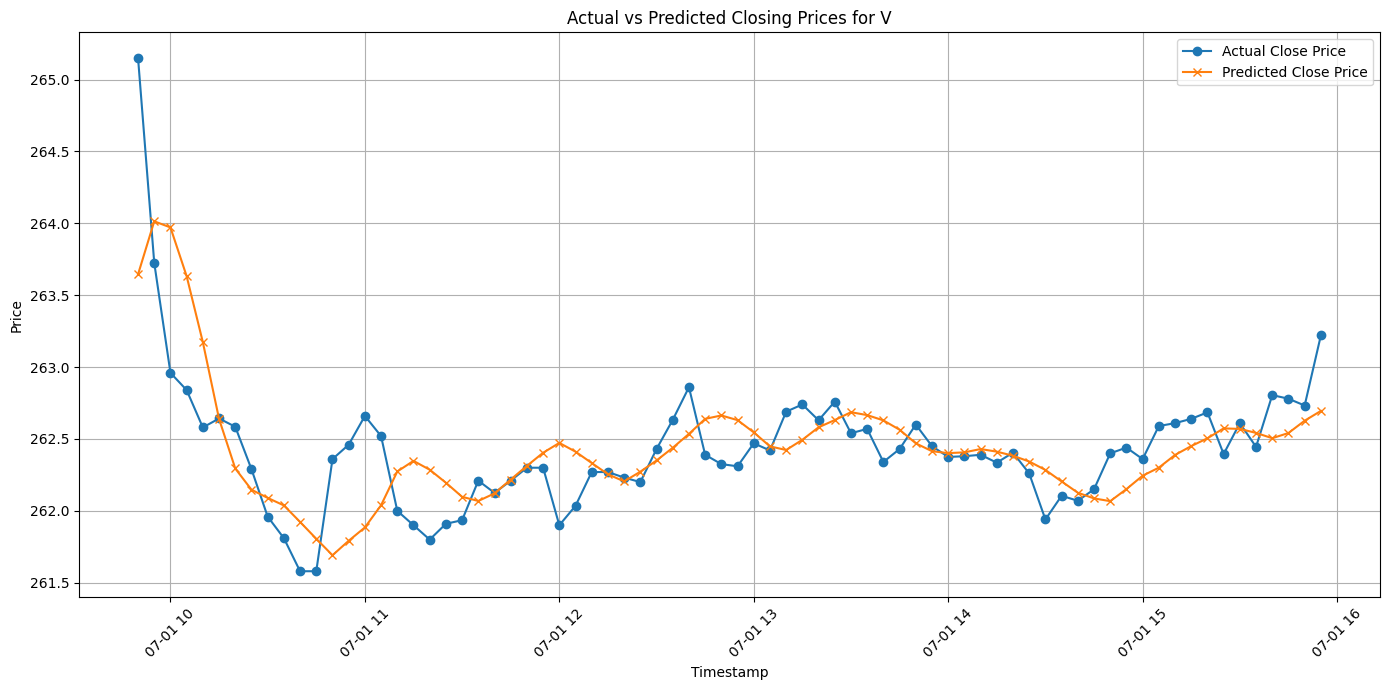

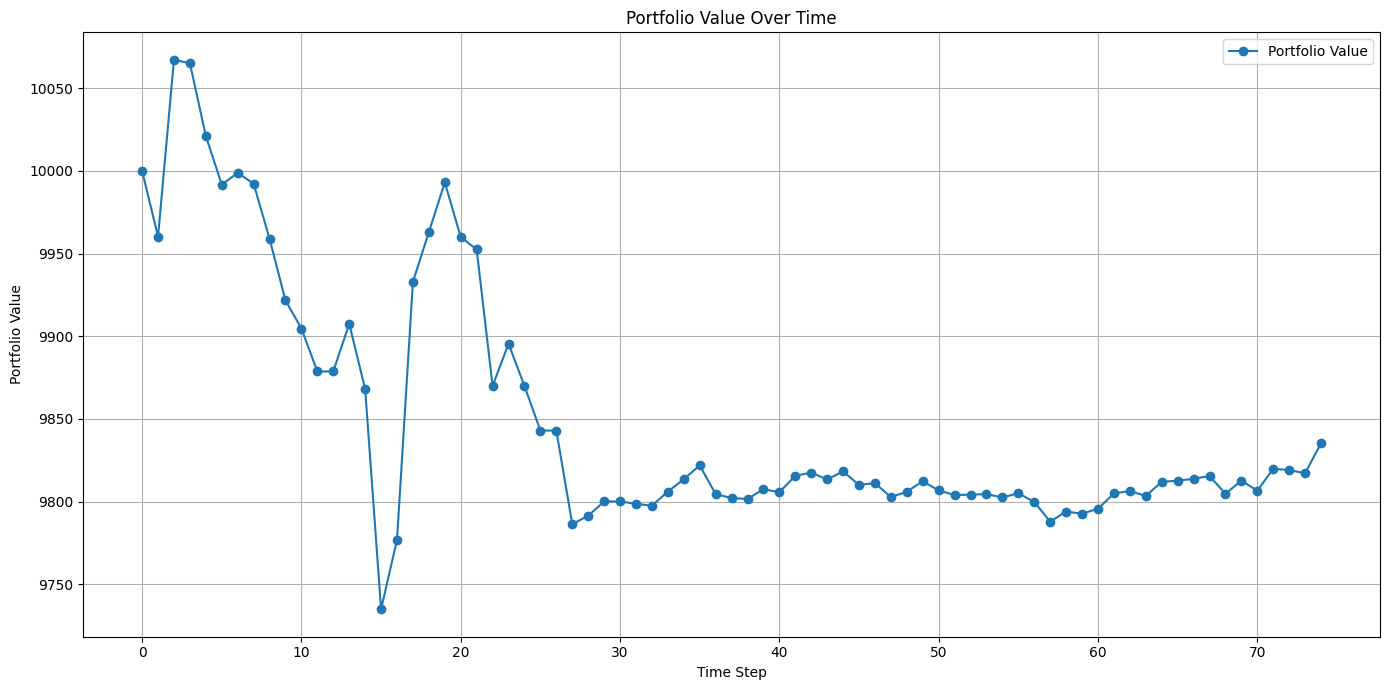

Stock: V
Initial Cash: 10000
Final Portfolio Value: 9835.284002807632
Returns: -1.65%
Transactions: [('short_sell', 75.0, 264.61969390869143), ('buy', 113.0, 263.48591143798825), ('cover_short', 75.0, 263.3656763305664), ('sell', 113.0, 261.83526538085937), ('short_sell', 75.0, 261.935071472168), ('short_sell', 225.0, 262.13468365478514), ('buy', 337.0, 262.4237938842773)]




In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import concurrent.futures

SEQ_LENGTH = 4
MAX_POSITION_SIZE = 1000  # Maximum number of shares to buy/sell at once
TRANSACTION_COST = 0.001  # 0.1% transaction cost
MARGIN_REQUIREMENT = 0.5  # 50% margin requirement for short selling
SLIPPAGE = 0.001  # 0.1% slippage

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='5m', start_date='2023-06-23', end_date='2024-07-02'):
    try:
        data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
        if data.empty:
            raise ValueError(f"No data found for {stock_code} with the given parameters.")
        data['RSI'] = compute_rsi(data['Close'])
        data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
        return data
    except Exception as e:
        print(f"Error fetching data for {stock_code}: {e}")
        return pd.DataFrame()

# Function to compute RSI
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if (col not in data.columns) or (data[col].isnull().any()):
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    short_shares = 0
    transactions = []
    portfolio_value = [initial_cash]

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            
            # Adjust for transaction costs and slippage
            buy_price = current_price * (1 + TRANSACTION_COST + SLIPPAGE)
            sell_price = current_price * (1 - TRANSACTION_COST - SLIPPAGE)
            
            # Trading logic
            if predicted_price > buy_price and cash > buy_price:
                shares_to_buy = min(cash // buy_price, MAX_POSITION_SIZE)
                if shares_to_buy > 0:
                    cash -= shares_to_buy * buy_price
                    shares += shares_to_buy
                    transactions.append(('buy', shares_to_buy, buy_price))
            
            elif predicted_price < sell_price and shares > 0:
                shares_to_sell = min(shares, MAX_POSITION_SIZE)
                if shares_to_sell > 0:
                    cash += shares_to_sell * sell_price
                    shares -= shares_to_sell
                    transactions.append(('sell', shares_to_sell, sell_price))
            
            # Short selling logic
            elif predicted_price < sell_price and cash > sell_price * MARGIN_REQUIREMENT:
                shares_to_short = min(cash // (sell_price * MARGIN_REQUIREMENT), MAX_POSITION_SIZE)
                if shares_to_short > 0:
                    cash += shares_to_short * sell_price
                    short_shares += shares_to_short
                    transactions.append(('short_sell', shares_to_short, sell_price))
            
            elif predicted_price > buy_price and short_shares > 0:
                shares_to_cover = min(short_shares, MAX_POSITION_SIZE)
                if shares_to_cover > 0:
                    cash -= shares_to_cover * buy_price
                    short_shares -= shares_to_cover
                    transactions.append(('cover_short', shares_to_cover, buy_price))
        
        # Calculate current portfolio value and append to the list
        current_portfolio_value = cash + shares * current_price - short_shares * current_price
        portfolio_value.append(current_portfolio_value)

    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1] - short_shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions, portfolio_value

# Function to backtest trading strategy
def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='5m', start_date=start_date, end_date=end_date)
    if historical_data.empty:
        print(f"Skipping backtesting for {stock_code} due to data fetching issues.")
        return None
    
    # Debug print to check the data range
    print(f"Historical data range for {stock_code}: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points for {stock_code}: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions, portfolio_value = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value for {stock_code}: {final_portfolio_value}")
    print(f"Returns for {stock_code}: {returns * 100:.2f}%")
    print(f"Transactions for {stock_code}: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
    
    # Plotting predicted vs actual prices
    plt.figure(figsize=(14, 7))
    plt.plot(timestamps, actual_prices, label='Actual Close Price', marker='o')
    plt.plot(timestamps, predicted_prices, label='Predicted Close Price', marker='x')
    plt.title(f'Actual vs Predicted Closing Prices for {stock_code}')
    plt.xlabel('Timestamp')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plotting portfolio value over time
    plt.figure(figsize=(14, 7))
    plt.plot(portfolio_value, label='Portfolio Value', marker='o')
    plt.title('Portfolio Value Over Time')
    plt.xlabel('Time Step')
    plt.ylabel('Portfolio Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return {
        'stock_code': stock_code,
        'initial_cash': initial_cash,
        'final_portfolio_value': final_portfolio_value,
        'returns': returns,
        'transactions': transactions,
        'portfolio_value': portfolio_value
    }

# List of top 5 DOW JONES stocks based on previous analysis
top_5_dow_jones_stocks = ['AAPL', 'MSFT', 'JNJ', 'V', 'WMT']

# Function to backtest a single stock
def backtest_single_stock(stock_code):
    model_path = f'model_{stock_code}.keras'
    scaler_path = f'scaler_{stock_code}.pkl'
    start_date = '2024-07-01'
    end_date = '2024-07-02'
    
    print(f"Backtesting for {stock_code}")
    result = backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date)
    if result:
        return result
    return None

# Backtest trading strategy for each of the top 5 stocks in parallel
results = []
with concurrent.futures.ThreadPoolExecutor() as executor:
    futures = [executor.submit(backtest_single_stock, stock) for stock in top_5_dow_jones_stocks]
    for future in concurrent.futures.as_completed(futures):
        result = future.result()
        if result:
            results.append(result)

# Sort results by returns and report the top 3
top_3_results = sorted(results, key=lambda x: x['returns'], reverse=True)[:3]

# Print overall results
for result in top_3_results:
    print(f"Stock: {result['stock_code']}")
    print(f"Initial Cash: {result['initial_cash']}")
    print(f"Final Portfolio Value: {result['final_portfolio_value']}")
    print(f"Returns: {result['returns'] * 100:.2f}%")
    print(f"Transactions: {result['transactions']}")
    print("\n")


In [1]:
import alpaca_trade_api as tradeapi
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import datetime
import time
import logging

# Replace with your API key details
API_KEY = 'PKS83XYYEBQDAQUMC11P'
API_SECRET = 'phV8PZYN9xZsubzhH3xBAjaqKAC4hW54VwdXKHq6'
APCA_API_BASE_URL = 'https://paper-api.alpaca.markets'  # Paper trading base URL

# Initialize API connection
api = tradeapi.REST(API_KEY, API_SECRET, APCA_API_BASE_URL, api_version='v2')

# Setup logging
logging.basicConfig(filename='trading_log.log', level=logging.INFO,
                    format='%(asctime)s - %(levelname)s - %(message)s')

# Load model and scaler
model = load_model('model_V.keras')  # Using the model for the best-performing stock, e.g., Visa
scaler = joblib.load('scaler_V.pkl')  # Corresponding scaler

SEQ_LENGTH = 4
MAX_POSITION_SIZE = 1000  # Maximum number of shares to buy/sell at once
TRANSACTION_COST = 0.001  # 0.1% transaction cost
SLIPPAGE = 0.001  # 0.1% slippage

def compute_rsi(prices, window=14):
    delta = prices.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def compute_macd(prices, slow=26, fast=12, signal=9):
    exp1 = prices.ewm(span=fast, adjust=False).mean()
    exp2 = prices.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

def fetch_data_yf(symbol, interval='5m', period='5d'):
    df = yf.download(tickers=symbol, interval=interval, period=period)
    df = df[['Open', 'High', 'Low', 'Close', 'Volume']]

    # Calculate RSI and MACD
    df['RSI'] = compute_rsi(df['Close'])
    macd, macd_signal = compute_macd(df['Close'])
    df['MACD'] = macd
    df['MACD_Signal'] = macd_signal

    return df

def preprocess_data_for_prediction(data, scaler):
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

def predict_next_closing_price(data_for_prediction):
    data_for_prediction = np.array([data_for_prediction[-SEQ_LENGTH:]])  # Reshape for the model
    predicted_price_scaled = model.predict(data_for_prediction)
    features_dummy = np.zeros((1, 7))
    features_dummy[:, 3] = predicted_price_scaled[0, 0]  # Assuming 'Close' is the 4th column
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    return predicted_price[0]

def execute_trade(symbol, prediction, current_price):
    account = api.get_account()
    cash = float(account.cash)

    if prediction > current_price * (1 + TRANSACTION_COST + SLIPPAGE):
        qty_to_trade = min(int(cash / current_price), MAX_POSITION_SIZE)
        if qty_to_trade > 0:
            print(f"Buying {qty_to_trade} shares at {current_price}")
            api.submit_order(symbol=symbol, qty=qty_to_trade, side='buy', type='market', time_in_force='gtc')
            logging.info(f"Bought {qty_to_trade} shares of {symbol} at {current_price}")
        else:
            logging.warning(f"Not enough cash to buy shares of {symbol} at {current_price}")
    elif prediction < current_price * (1 - TRANSACTION_COST - SLIPPAGE):
        # Check how many shares we currently hold
        position = api.get_position(symbol)
        shares_held = int(position.qty) if position else 0
        qty_to_trade = min(shares_held, MAX_POSITION_SIZE)
        if qty_to_trade > 0:
            print(f"Selling {qty_to_trade} shares at {current_price}")
            api.submit_order(symbol=symbol, qty=qty_to_trade, side='sell', type='market', time_in_force='gtc')
            logging.info(f"Sold {qty_to_trade} shares of {symbol} at {current_price}")
        else:
            logging.warning(f"No shares of {symbol} to sell at {current_price}")

def align_to_interval():
    now = datetime.datetime.now()
    wait_time = 1800 - (now.minute * 60 + now.second) % 1800  # Wait time until the next half-hour mark
    time.sleep(wait_time)

try:
    while True:
        align_to_interval()  # Align execution to 30-minute intervals
        current_time = datetime.datetime.now()
        start_time = current_time - datetime.timedelta(minutes=30)
        
        # Fetch and process the data
        data = fetch_data_yf('V', period='5d')
        preprocessed_data = preprocess_data_for_prediction(data, scaler)
        
        # Predict and execute trades
        prediction = predict_next_closing_price(preprocessed_data)
        execute_trade('V', prediction, data['Close'].iloc[-1])

except Exception as e:
    print(f"An error occurred: {e}")
    logging.error(f"An error occurred: {e}")


[*********************100%%**********************]  1 of 1 completed
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0


Historical data range for MSFT: 2024-07-01 09:30:00-04:00 to 2024-07-01 15:55:00-04:00
Number of data points for MSFT: 78
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


... (4 outputs left out)

C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_31384\3575954191.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━

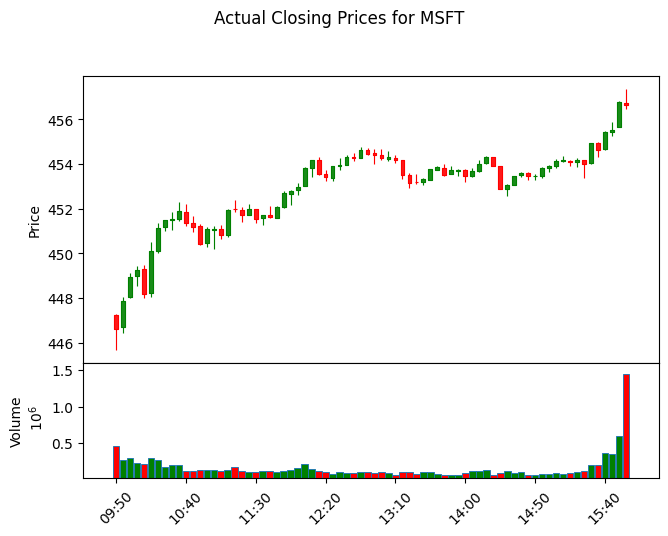

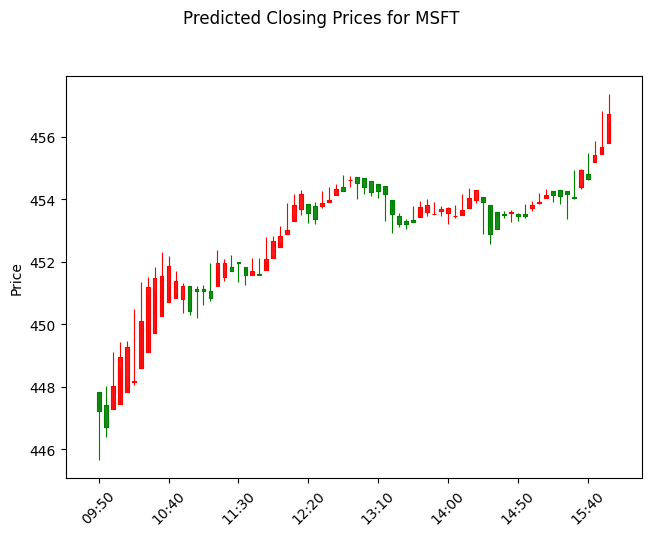

Stock: MSFT
Initial Cash: 10000
Final Portfolio Value: 9669.800478576683
Returns: -3.30%
Transactions: [('buy', 22.0, 448.1294553222655), ('sell', 22.0, 447.13393878173827), ('buy', 22.0, 451.34088244628896), ('sell', 22.0, 451.0660612182617), ('buy', 22.0, 452.6134114379882), ('sell', 22.0, 450.7916173095703), ('buy', 21.0, 452.4931763305663), ('sell', 21.0, 451.18581634521485), ('buy', 21.0, 454.46711755371086), ('sell', 21.0, 452.9822346191406), ('buy', 21.0, 455.18354388427724), ('sell', 21.0, 453.7207448730469), ('buy', 21.0, 455.41902978515617), ('sell', 21.0, 452.8425), ('buy', 21.0, 454.80779388427726), ('sell', 21.0, 452.68281634521486), ('buy', 21.0, 454.37694122314446), ('sell', 21.0, 452.9123673095703), ('buy', 21.0, 455.05327899169913), ('sell', 21.0, 454.0401121826172), ('buy', 21.0, 455.5592938842772), ('sell', 21.0, 454.5091734008789)]


In [5]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import mplfinance as mpf
import matplotlib.pyplot as plt

SEQ_LENGTH = 4
MAX_POSITION_SIZE = 1000  # Maximum number of shares to buy/sell at once
TRANSACTION_COST = 0.001  # 0.1% transaction cost
MARGIN_REQUIREMENT = 0.5  # 50% margin requirement for short selling
SLIPPAGE = 0.001  # 0.1% slippage

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='5m', start_date='2024-07-01', end_date='2024-07-02'):
    try:
        data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
        if data.empty:
            raise ValueError(f"No data found for {stock_code} with the given parameters.")
        data['RSI'] = compute_rsi(data['Close'])
        data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
        return data
    except Exception as e:
        print(f"Error fetching data for {stock_code}: {e}")
        return pd.DataFrame()

# Function to compute RSI
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if (col not in data.columns) or (data[col].isnull().any()):
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    transactions = []
    portfolio_value = [initial_cash]

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Open'].iloc[i + SEQ_LENGTH]
            
            # Adjust for transaction costs and slippage
            buy_price = current_price * (1 + TRANSACTION_COST + SLIPPAGE)
            sell_price = current_price * (1 - TRANSACTION_COST - SLIPPAGE)
            
            # Trading logic based on the provided rules
            if predicted_price > current_price and cash > buy_price:
                shares_to_buy = min(cash // buy_price, MAX_POSITION_SIZE)
                if shares_to_buy > 0:
                    cash -= shares_to_buy * buy_price
                    shares += shares_to_buy
                    transactions.append(('buy', shares_to_buy, buy_price))
            
            elif predicted_price < current_price and shares > 0:
                shares_to_sell = min(shares, MAX_POSITION_SIZE)
                if shares_to_sell > 0:
                    cash += shares_to_sell * sell_price
                    shares -= shares_to_sell
                    transactions.append(('sell', shares_to_sell, sell_price))
        
        # Calculate current portfolio value and append to the list
        current_portfolio_value = cash + shares * historical_data['Close'].iloc[i + SEQ_LENGTH]
        portfolio_value.append(current_portfolio_value)

    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions, portfolio_value

# Function to backtest trading strategy
def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='5m', start_date=start_date, end_date=end_date)
    if historical_data.empty:
        print(f"Skipping backtesting for {stock_code} due to data fetching issues.")
        return None
    
    # Debug print to check the data range
    print(f"Historical data range for {stock_code}: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points for {stock_code}: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions, portfolio_value = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value for {stock_code}: {final_portfolio_value}")
    print(f"Returns for {stock_code}: {returns * 100:.2f}%")
    print(f"Transactions for {stock_code}: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    open_prices = []
    high_prices = []
    low_prices = []
    predicted_candles = []

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            open_price = historical_data['Open'].iloc[i + SEQ_LENGTH]
            high_price = historical_data['High'].iloc[i + SEQ_LENGTH]
            low_price = historical_data['Low'].iloc[i + SEQ_LENGTH]

            predicted_candles.append((timestamp, open_price, high_price, low_price, predicted_price))
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
            open_prices.append(open_price)
            high_prices.append(high_price)
            low_prices.append(low_price)
    
    actual_candles = historical_data.iloc[-len(predicted_candles):][['Open', 'High', 'Low', 'Close', 'Volume']].copy()
    predicted_candles_df = pd.DataFrame(predicted_candles, columns=['Date', 'Open', 'High', 'Low', 'Close']).set_index('Date')
    
    # Plotting candlestick charts
    mc = mpf.make_marketcolors(up='g', down='r', wick={'up':'g', 'down':'r'}, edge={'up':'g', 'down':'r'}, volume='in')
    s = mpf.make_mpf_style(marketcolors=mc)
    
    # Plot actual candlestick chart
    actual_plot = mpf.plot(actual_candles, type='candle', style=s, title=f"Actual Closing Prices for {stock_code}", ylabel='Price', ylabel_lower='Volume', volume=True)

    # Plot predicted candlestick chart
    predicted_plot = mpf.plot(predicted_candles_df, type='candle', style=s, title=f"Predicted Closing Prices for {stock_code}", ylabel='Price')

    return {
        'stock_code': stock_code,
        'initial_cash': initial_cash,
        'final_portfolio_value': final_portfolio_value,
        'returns': returns,
        'transactions': transactions,
        'portfolio_value': portfolio_value
    }

# Backtest trading strategy for MSFT
result = backtest_trading_strategy('MSFT', 'model_MSFT.keras', 'scaler_MSFT.pkl', '2024-07-01', '2024-07-02')

if result:
    print(f"Stock: {result['stock_code']}")
    print(f"Initial Cash: {result['initial_cash']}")
    print(f"Final Portfolio Value: {result['final_portfolio_value']}")
    print(f"Returns: {result['returns'] * 100:.2f}%")
    print(f"Transactions: {result['transactions']}")
